View 01 keypoint sayısı: 1349
View 02 keypoint sayısı: 979
İyi eşleşme sayısı: 72


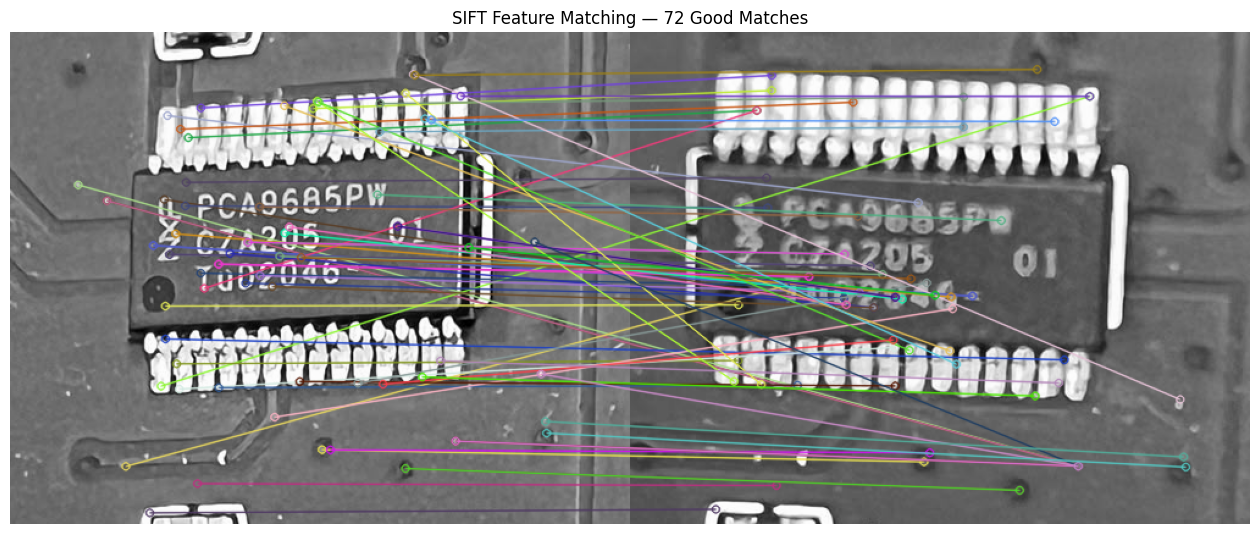

In [1]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt

# Proje dizinleri
project_root = Path.cwd().parent
data_dir = project_root / "data" / "raw" / "pcb_component_crops"

component_dir = data_dir / "component_1_upper_PCA9685"

# Aynı komponentin iki farklı açıdan görüntüsü
img1_path = component_dir / "view_01.png"
img2_path = component_dir / "view_02.png"

# Doğrudan grayscale oku
img1 = cv2.imread(str(img1_path), cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread(str(img2_path), cv2.IMREAD_GRAYSCALE)

if img1 is None or img2 is None:
    raise FileNotFoundError(
        f"Görüntüler okunamadı:\n{img1_path}\n{img2_path}"
    )

# SIFT oluştur
sift = cv2.SIFT_create()

# Keypoint ve descriptor çıkar
kp1, des1 = sift.detectAndCompute(img1, None)
kp2, des2 = sift.detectAndCompute(img2, None)

print("View 01 keypoint sayısı:", len(kp1))
print("View 02 keypoint sayısı:", len(kp2))

if des1 is None or des2 is None:
    raise ValueError("Görüntülerden birinde SIFT descriptor bulunamadı.")

# FLANN matcher
index_params = dict(algorithm=1, trees=5)
search_params = dict(checks=50)

flann = cv2.FlannBasedMatcher(index_params, search_params)

# Her descriptor için en yakın iki eşleşmeyi bul
matches = flann.knnMatch(des1, des2, k=2)

# Lowe ratio test
good_matches = []

for pair in matches:
    if len(pair) == 2:
        m, n = pair

        if m.distance < 0.75 * n.distance:
            good_matches.append(m)

print("İyi eşleşme sayısı:", len(good_matches))

# Eşleşmeleri görselleştir
matched_img = cv2.drawMatches(
    img1, kp1,
    img2, kp2,
    good_matches,
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(16, 8))
plt.imshow(cv2.cvtColor(matched_img, cv2.COLOR_BGR2RGB))
plt.title(f"SIFT Feature Matching — {len(good_matches)} Good Matches")
plt.axis("off")
plt.show()

Good matches: 72
RANSAC inliers: 18
RANSAC outliers: 54
Inlier ratio: %25.00

Homography matrisi:
[[ 6.94651664e-01 -8.51541844e-02  6.85873085e+01]
 [-6.62555880e-02  7.28250260e-01  3.37995174e+01]
 [-1.14355478e-04 -4.37688586e-04  1.00000000e+00]]


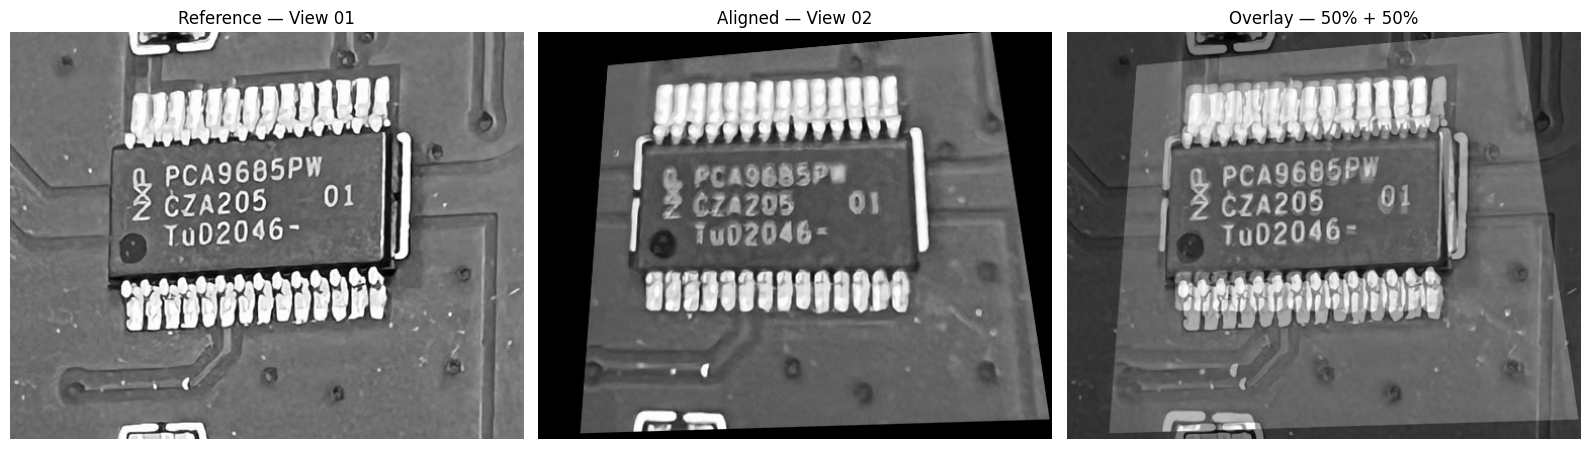

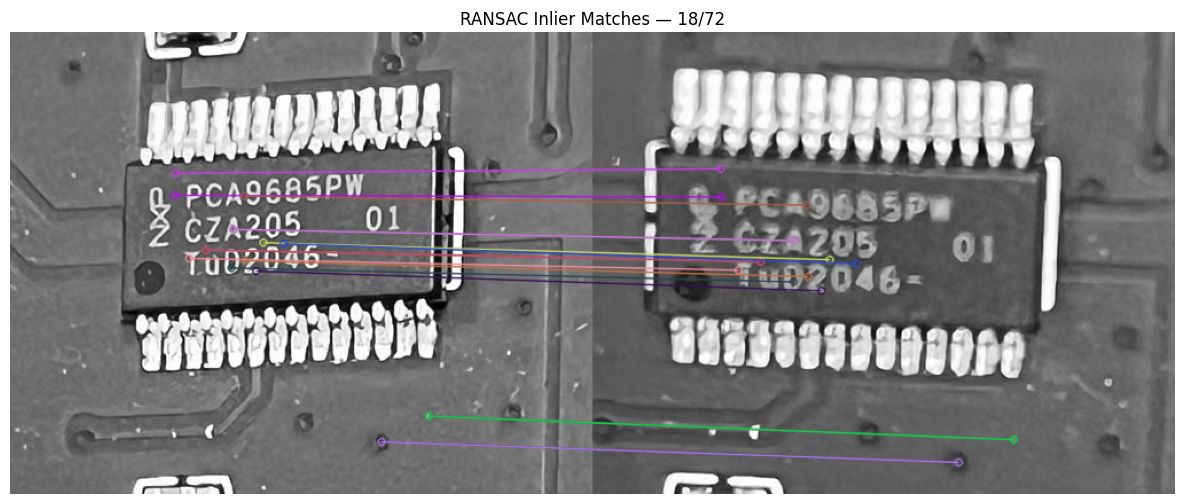

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Eşleşen noktaların koordinatları
# img2 (source) -> img1 (reference)

src_pts = np.float32([
    kp2[m.trainIdx].pt for m in good_matches
]).reshape(-1, 1, 2)

dst_pts = np.float32([
    kp1[m.queryIdx].pt for m in good_matches
]).reshape(-1, 1, 2)

if len(good_matches) < 4:
    raise ValueError("Homography için en az 4 eşleşme gerekli.")

# 2. RANSAC ile homography hesapla
H, mask = cv2.findHomography(
    src_pts,
    dst_pts,
    cv2.RANSAC,
    ransacReprojThreshold=3.0
)

if H is None or mask is None:
    raise RuntimeError("Homography hesaplanamadı.")

inlier_mask = mask.ravel().astype(bool)

inliers = int(inlier_mask.sum())
total = len(good_matches)
inlier_ratio = inliers / total

print("Good matches:", total)
print("RANSAC inliers:", inliers)
print("RANSAC outliers:", total - inliers)
print(f"Inlier ratio: %{inlier_ratio * 100:.2f}")

print("\nHomography matrisi:")
print(H)

# 3. View 02'yi View 01 koordinatlarına dönüştür
h1, w1 = img1.shape

aligned = cv2.warpPerspective(
    img2,
    H,
    (w1, h1)
)

# 4. Görsel karşılaştırma
overlay = cv2.addWeighted(
    img1, 0.5,
    aligned, 0.5,
    0
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(img1, cmap="gray")
axes[0].set_title("Reference — View 01")

axes[1].imshow(aligned, cmap="gray")
axes[1].set_title("Aligned — View 02")

axes[2].imshow(overlay, cmap="gray")
axes[2].set_title("Overlay — 50% + 50%")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# 5. Yalnızca RANSAC inlier eşleşmelerini çiz
inlier_matches = [
    m for m, keep in zip(good_matches, inlier_mask)
    if keep
]

inlier_vis = cv2.drawMatches(
    img1, kp1,
    img2, kp2,
    inlier_matches,
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(16, 6))
plt.imshow(cv2.cvtColor(inlier_vis, cv2.COLOR_BGR2RGB))
plt.title(f"RANSAC Inlier Matches — {inliers}/{total}")
plt.axis("off")
plt.show()